# LAB 3 – Bài 3 (Trang 7, câu d → hết): Neural Network phân lớp MNIST bằng k-fold cross validation
Các câu a, b, c (đọc dữ liệu, in kích thước, chuẩn hóa) được thực hiện lại ở đầu bài để notebook chạy độc lập.

In [1]:
HO_TEN = "Trang Kim Đạt"
MSSV = "6451071018"
print(f"{HO_TEN} – {MSSV}")

Trang Kim Đạt – 6451071018


In [2]:
print(f"{HO_TEN} – {MSSV}")
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout, Input
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

np.random.seed(42)
tf.keras.utils.set_random_seed(42)

Trang Kim Đạt – 6451071018


c:\Users\trang\AppData\Local\Programs\Python\Python311\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.9) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


In [3]:
print(f"{HO_TEN} – {MSSV}")
def danh_gia(ten_mo_hinh, y_true, y_pred, target_names=None):
    """In Accuracy, Precision/Recall/F1 (từng lớp + trung bình) và vẽ confusion matrix dạng heatmap."""
    print(f"===== {ten_mo_hinh} =====")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print(classification_report(y_true, y_pred, target_names=target_names, digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=target_names if target_names is not None else "auto",
                yticklabels=target_names if target_names is not None else "auto")
    plt.xlabel("Nhãn dự đoán")
    plt.ylabel("Nhãn thực tế")
    plt.title(f"Confusion matrix - {ten_mo_hinh}")
    plt.show()

Trang Kim Đạt – 6451071018


### Câu a, b, c (chuẩn bị dữ liệu)

In [4]:
print(f"{HO_TEN} – {MSSV}")
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
print("train:", train_images.shape, train_labels.shape, "| test:", test_images.shape, test_labels.shape)
train_images = train_images / 255.0
test_images = test_images / 255.0

Trang Kim Đạt – 6451071018
train: (60000, 28, 28) (60000,) | test: (10000, 28, 28) (10000,)


## Câu d) Hàm `create_model`

In [5]:
print(f"{HO_TEN} – {MSSV}")
def create_model():
    model = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation="relu"),
        Dropout(0.2),
        Dense(10, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

create_model().summary()

Trang Kim Đạt – 6451071018


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Câu e) Huấn luyện bằng 10-fold cross validation (epoch = 5, batch_size = 32)

In [6]:
print(f"{HO_TEN} – {MSSV}")
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
models, accuracy_per_fold, loss_per_fold = [], [], []

for fold, (train_index, val_index) in enumerate(kfold.split(train_images), start=1):
    model = create_model()
    X_train_fold, X_val_fold = train_images[train_index], train_images[val_index]
    y_train_fold, y_val_fold = train_labels[train_index], train_labels[val_index]
    model.fit(X_train_fold, y_train_fold, validation_data=(X_val_fold, y_val_fold),
              epochs=5, batch_size=32, verbose=0)
    loss, acc = model.evaluate(X_val_fold, y_val_fold, verbose=0)
    models.append(model)
    accuracy_per_fold.append(acc)
    loss_per_fold.append(loss)
    print(f"Fold {fold:2d}: loss = {loss:.4f} - accuracy = {acc:.4f}")

Trang Kim Đạt – 6451071018
Fold  1: loss = 0.0716 - accuracy = 0.9780
Fold  2: loss = 0.0997 - accuracy = 0.9712
Fold  3: loss = 0.0922 - accuracy = 0.9723
Fold  4: loss = 0.0817 - accuracy = 0.9755
Fold  5: loss = 0.1004 - accuracy = 0.9707
Fold  6: loss = 0.0881 - accuracy = 0.9752
Fold  7: loss = 0.0919 - accuracy = 0.9725
Fold  8: loss = 0.0861 - accuracy = 0.9742
Fold  9: loss = 0.0980 - accuracy = 0.9707
Fold 10: loss = 0.0822 - accuracy = 0.9748


## Câu f) Mean / Std của Accuracy và Loss

In [7]:
print(f"{HO_TEN} – {MSSV}")
print(f"Mean Accuracy : {np.mean(accuracy_per_fold):.4f}")
print(f"Std Accuracy   : {np.std(accuracy_per_fold):.4f}")
print(f"Mean Loss      : {np.mean(loss_per_fold):.4f}")
print(f"Std Loss       : {np.std(loss_per_fold):.4f}")

Trang Kim Đạt – 6451071018
Mean Accuracy : 0.9735
Std Accuracy   : 0.0023
Mean Loss      : 0.0892
Std Loss       : 0.0087


## Câu g) Biểu đồ accuracy, loss sau mỗi fold

Trang Kim Đạt – 6451071018


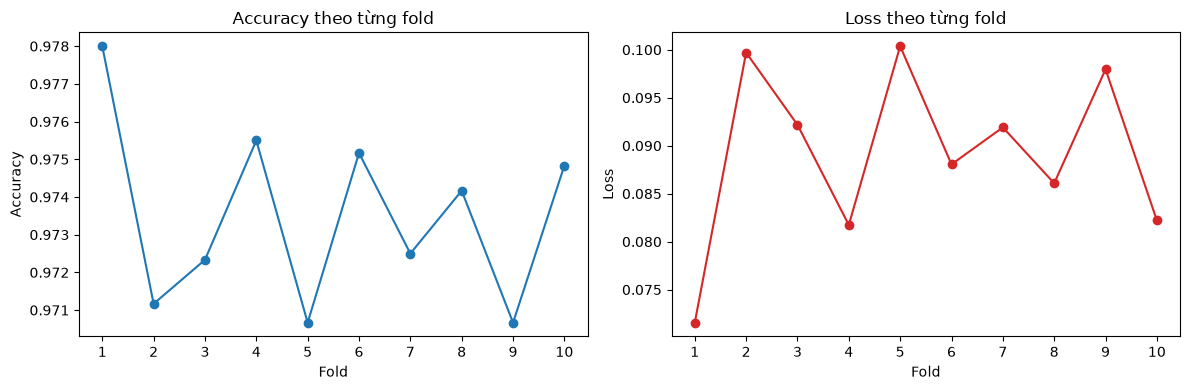

In [8]:
print(f"{HO_TEN} – {MSSV}")
folds = range(1, len(accuracy_per_fold) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(folds, accuracy_per_fold, "o-", color="tab:blue")
ax[0].set_title("Accuracy theo từng fold"); ax[0].set_xlabel("Fold"); ax[0].set_ylabel("Accuracy"); ax[0].set_xticks(list(folds))
ax[1].plot(folds, loss_per_fold, "o-", color="tab:red")
ax[1].set_title("Loss theo từng fold"); ax[1].set_xlabel("Fold"); ax[1].set_ylabel("Loss"); ax[1].set_xticks(list(folds))
plt.tight_layout(); plt.show()

## Câu h) Dùng mô hình có Accuracy tốt nhất giữa các fold để phân lớp tập test

In [9]:
print(f"{HO_TEN} – {MSSV}")
best_index = int(np.argmax(accuracy_per_fold))
best_model = models[best_index]
print(f"Mô hình tốt nhất: fold {best_index + 1} (accuracy = {accuracy_per_fold[best_index]:.4f})")
y_prob = best_model.predict(test_images)
y_pred = np.argmax(y_prob, axis=1)

Trang Kim Đạt – 6451071018
Mô hình tốt nhất: fold 1 (accuracy = 0.9780)
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 744us/step


## Câu i, j, k) Accuracy, Precision/Recall/F1-score, Confusion matrix trên tập test

Trang Kim Đạt – 6451071018
===== Best fold model - MNIST =====
Accuracy: 0.9764
              precision    recall  f1-score   support

           0     0.9720    0.9929    0.9823       980
           1     0.9860    0.9921    0.9890      1135
           2     0.9683    0.9767    0.9725      1032
           3     0.9760    0.9663    0.9711      1010
           4     0.9816    0.9766    0.9791       982
           5     0.9720    0.9742    0.9731       892
           6     0.9793    0.9854    0.9823       958
           7     0.9719    0.9747    0.9733      1028
           8     0.9821    0.9589    0.9704       974
           9     0.9740    0.9643    0.9691      1009

    accuracy                         0.9764     10000
   macro avg     0.9763    0.9762    0.9762     10000
weighted avg     0.9764    0.9764    0.9764     10000



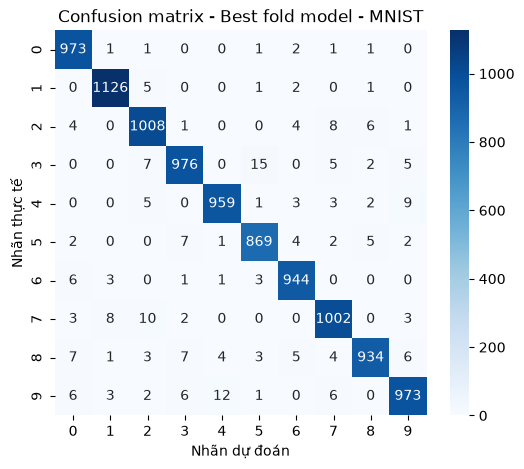

In [10]:
print(f"{HO_TEN} – {MSSV}")
danh_gia("Best fold model - MNIST", test_labels, y_pred, [str(i) for i in range(10)])

## Câu l) Kết quả phân lớp của 05 ảnh đầu tiên trong tập test

Trang Kim Đạt – 6451071018
Ảnh 0: nhãn thực tế = 7, dự đoán = 7
Ảnh 1: nhãn thực tế = 2, dự đoán = 2
Ảnh 2: nhãn thực tế = 1, dự đoán = 1
Ảnh 3: nhãn thực tế = 0, dự đoán = 0
Ảnh 4: nhãn thực tế = 4, dự đoán = 4


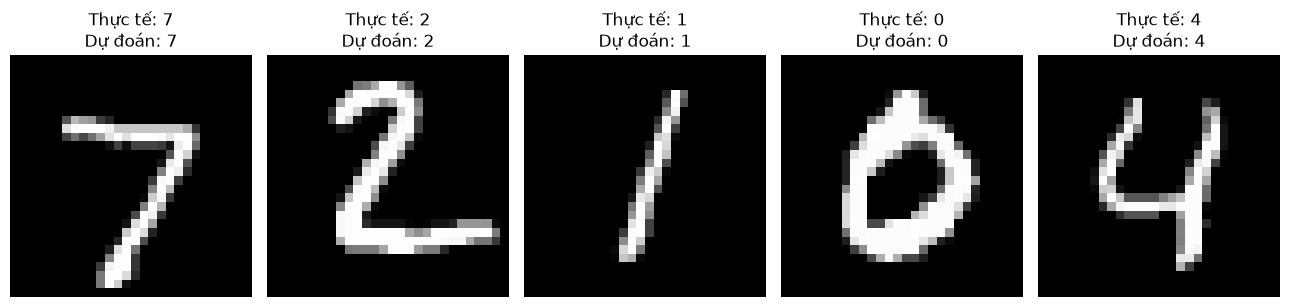

In [11]:
print(f"{HO_TEN} – {MSSV}")
fig, axes = plt.subplots(1, 5, figsize=(13, 3))
for image_index in range(5):
    anh = np.expand_dims(test_images[image_index], axis=0)
    du_doan = np.argmax(best_model.predict(anh, verbose=0), axis=1)[0]
    axes[image_index].imshow(test_images[image_index], cmap="gray")
    axes[image_index].set_title(f"Thực tế: {test_labels[image_index]}\nDự đoán: {du_doan}")
    axes[image_index].axis("off")
    print(f"Ảnh {image_index}: nhãn thực tế = {test_labels[image_index]}, dự đoán = {du_doan}")
plt.tight_layout(); plt.show()